# AlphaRAD on combined dataset (CheXpert + VinDr-CXR)


In [1]:
# Install dependencies
import subprocess
import sys
import time
from pathlib import Path

RUN_START = time.perf_counter()
REPO_URL = 'https://github.com/jz5426/ECCV-2026-AlphaRAD.git'
REPO_COMMIT = '59a28b0211081a99936da37902b3e5ee081056f5'
REPO = Path('/kaggle/working/alpharad_official')
INPUT = Path('/kaggle/input')
RESULTS = Path('/kaggle/working/alpharad_combined_results')
RESULTS.mkdir(parents=True, exist_ok=True)

packages = [
    'albumentations==1.3.1', 'transformers==4.57.1',
    'torchmetrics==1.8.2', 'jaxtyping==0.3.3',
    'huggingface_hub==0.36.0', 'hydra-core==1.3.2',
    'einops', 'nltk', 'timm==0.9.2',
]
print('Installing AlphaRAD dependencies...', flush=True)
subprocess.run(
    [sys.executable, '-m', 'pip', 'install', '--progress-bar', 'off',
     '--disable-pip-version-check', *packages],
    check=True, timeout=1200,
)
if not (REPO / 'evaluate_zeroshot.py').is_file():
    print('Cloning AlphaRAD source...', flush=True)
    subprocess.run(['git', 'clone', REPO_URL, str(REPO)], check=True, timeout=300)
subprocess.run(['git', '-C', str(REPO), 'checkout', '--detach', REPO_COMMIT], check=True)
actual_commit = subprocess.check_output(['git', '-C', str(REPO), 'rev-parse', 'HEAD'], text=True).strip()
if actual_commit != REPO_COMMIT:
    raise ValueError(f'Unexpected AlphaRAD source commit: {actual_commit}')
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
print('AlphaRAD source:', actual_commit, flush=True)


Installing AlphaRAD dependencies...
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 1.29.0
    Uninstalling huggingface_hub-1.29.0:
      Successfully uninstalled huggingface_hub-1.29.0
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.23.1
    Uninstalling tokenizers-0.23.1:
      Successfully uninstalled tokenizers-0.23.1
  Attempting uninstall: transformers
    Found existing installation: transformers 5.16.1
    Uninstalling transformers-5.16.1:
      Successfully uninstalled transformers-5.16.1
  Attempting uninstall: albumentations
    Found existing installation: albumentations 2.0.8
    Uninstalling albumentations-2.0.8:
      Successfully uninstalled albumentations-2.0.8
  Attempting uninstall: torchmetrics
    Found existing installation: torchmetrics 1.9.0
    Uninstalling torchmetrics-1.9.0:
      Successfully uninstalled torchmetrics-1.9.0
  Attempting uninstall: timm
    Found existing installation: t

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.0 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.0 which is incompatible.


Cloning AlphaRAD source...


Cloning into '/kaggle/working/alpharad_official'...


AlphaRAD source: 59a28b0211081a99936da37902b3e5ee081056f5


HEAD is now at 59a28b0 .


In [2]:
# Find the combined archive and verify its four-label test manifest
import hashlib
import json
import shutil
import zipfile

import numpy as np
import pandas as pd
import torch
from PIL import Image

ZIP_PATH = ''
ZIP_NAME = 'chexpert_vindr_combined.zip'
LABELS = ['Atelectasis', 'Cardiomegaly', 'Consolidation', 'Pleural Effusion']
KEYS = ['atelectasis', 'cardiomegaly', 'consolidation', 'pleural_effusion']
TARGETS = ['target_' + key for key in KEYS]
MASKS = ['mask_' + key for key in KEYS]
if ZIP_PATH:
    ARCHIVE_PATH = Path(ZIP_PATH)
else:
    matches = sorted(INPUT.rglob(ZIP_NAME))
    if len(matches) != 1:
        raise FileNotFoundError(f'Attach one {ZIP_NAME} output or set ZIP_PATH; found {len(matches)} copies.')
    ARCHIVE_PATH = matches[0]
if not zipfile.is_zipfile(ARCHIVE_PATH):
    raise ValueError(f'Not a valid ZIP archive: {ARCHIVE_PATH}')

with zipfile.ZipFile(ARCHIVE_PATH) as archive:
    names = set(archive.namelist())
    test_files = sorted(name for name in names if name.endswith('test/labels.csv'))
    if len(test_files) != 1:
        raise FileNotFoundError(f'Expected one test/labels.csv; found {len(test_files)}. ZIP entries: {sorted(names)[:12]}')
    archive_prefix = test_files[0][:-len('test/labels.csv')]
    settings_name = archive_prefix + 'settings.json'
    settings = json.loads(archive.read(settings_name)) if settings_name in names else None
    splits = {}
    for split in ['train', 'validation', 'test']:
        label_file = archive_prefix + split + '/labels.csv'
        if label_file not in names:
            raise FileNotFoundError(f'Missing {label_file} in the attached ZIP.')
        splits[split] = pd.read_csv(archive.open(label_file))
    if settings is not None:
        if settings.get('labels') != LABELS or settings.get('targets') != TARGETS or settings.get('masks') != MASKS:
            raise ValueError('The ZIP settings do not match the expected four labels, targets, and masks.')
    required = {'sample_id', 'source_dataset', 'group_id', 'image_path', *TARGETS, *MASKS}
    for split, table in splits.items():
        if not required.issubset(table.columns):
            raise ValueError(f'{split}/labels.csv is missing {sorted(required - set(table.columns))}')
        if table['sample_id'].isna().any() or table['sample_id'].duplicated().any():
            raise ValueError(f'{split} contains missing or repeated sample IDs.')
    ids = [set(table['sample_id']) for table in splits.values()]
    if ids[0] & ids[1] or ids[0] & ids[2] or ids[1] & ids[2]:
        raise ValueError('A sample ID appears in more than one split.')
    groups = [set(table['group_id']) for table in splits.values()]
    if groups[0] & groups[1] or groups[0] & groups[2] or groups[1] & groups[2]:
        raise ValueError('A patient or image group appears in more than one split.')
    test_df = splits['test'].reset_index(drop=True).copy()
    if set(test_df['source_dataset']) != {'chexpert', 'vindr'}:
        raise ValueError('The test split must contain both CheXpert and VinDr images.')
    test_df['zip_image_path'] = test_df['image_path'].map(
        lambda value: str(value) if str(value) in names else archive_prefix + str(value).lstrip('/'))
    missing = set(test_df['zip_image_path']) - names
    if missing:
        raise FileNotFoundError(f'{len(missing)} test images are missing from the ZIP; example: {next(iter(missing))}')
    if test_df['zip_image_path'].duplicated().any():
        raise ValueError('The test split repeats an image path.')

for column in TARGETS + MASKS:
    test_df[column] = pd.to_numeric(test_df[column], errors='raise')
    if test_df[column].isna().any() or not test_df[column].isin([0, 1]).all():
        raise ValueError(f'{column} must contain only 0 and 1.')
    test_df[column] = test_df[column].astype(np.uint8)
if not torch.cuda.is_available():
    raise RuntimeError('Select a Kaggle GPU accelerator before inference.')
print('Combined archive:', ARCHIVE_PATH, flush=True)
print('Splits:', {name: len(table) for name, table in splits.items()}, flush=True)
print('Test sources:', test_df['source_dataset'].value_counts().to_dict(), flush=True)
print('GPU:', torch.cuda.get_device_name(0), flush=True)


Combined archive: /kaggle/input/notebooks/shadril238/chexpert-vindr-combined-image-dataset/chexpert_vindr_combined.zip
Splits: {'train': 19973, 'validation': 2526, 'test': 2501}
Test sources: {'vindr': 1500, 'chexpert': 1001}
GPU: Tesla T4


In [3]:
# Extract only held-out images for the official filesystem-based evaluator
TEMP_IMAGES = Path('/tmp/alpharad_combined_test_images')
TEMP_IMAGES.mkdir(parents=True, exist_ok=True)
local_paths = []
with zipfile.ZipFile(ARCHIVE_PATH) as archive:
    for number, name in enumerate(test_df['zip_image_path'], start=1):
        suffix = Path(name).suffix.lower()
        if suffix not in {'.png', '.jpg', '.jpeg'}:
            raise ValueError(f'Unsupported test image extension: {name}')
        local = TEMP_IMAGES / f'{number:05d}_{hashlib.sha1(name.encode()).hexdigest()[:12]}{suffix}'
        expected_bytes = archive.getinfo(name).file_size
        if not local.is_file() or local.stat().st_size != expected_bytes:
            with archive.open(name) as source, local.open('wb') as destination:
                shutil.copyfileobj(source, destination, length=1024 * 1024)
        local_paths.append(str(local))
        if number % 500 == 0 or number == len(test_df):
            print(f'Prepared {number:,}/{len(test_df):,} test images', flush=True)
test_df['local_image'] = local_paths
for source_name in ['chexpert', 'vindr']:
    sample = test_df.loc[test_df['source_dataset'].eq(source_name), 'local_image'].iloc[0]
    with Image.open(sample) as image:
        image.verify()
print('Test images ready for AlphaRAD.', flush=True)


Prepared 500/2,501 test images
Prepared 1,000/2,501 test images
Prepared 1,500/2,501 test images
Prepared 2,000/2,501 test images
Prepared 2,500/2,501 test images
Prepared 2,501/2,501 test images
Test images ready for AlphaRAD.


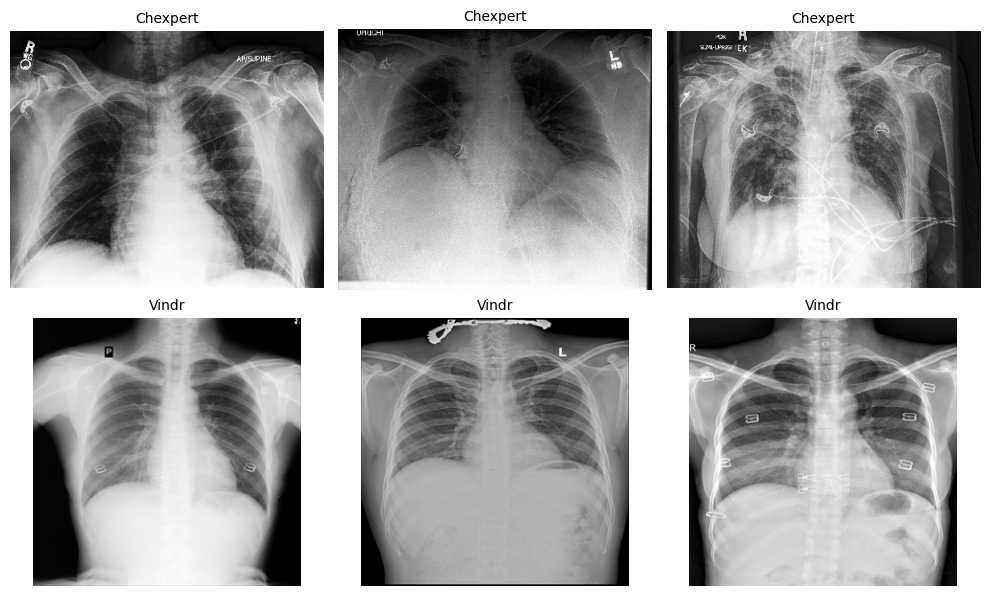

In [4]:
# Show example images from both parts of the combined test set
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for row, source_name in enumerate(['chexpert', 'vindr']):
    subset = test_df.loc[test_df['source_dataset'].eq(source_name)]
    selected = subset.sample(n=min(3, len(subset)), random_state=42)
    for column, (_, example) in enumerate(selected.iterrows()):
        with Image.open(example['local_image']) as image:
            axes[row, column].imshow(image.convert('L'), cmap='gray')
        axes[row, column].set_title(source_name.title(), fontsize=10)
        axes[row, column].axis('off')
fig.tight_layout()
fig.savefig(RESULTS / 'sample_images.png', dpi=160)
plt.show()
plt.close(fig)


In [5]:
# Load the released checkpoint and its exact image and text backbones
from huggingface_hub import HfApi, hf_hub_download, snapshot_download

api = HfApi()
MODEL_REPO = 'maxxyouu/AlphaRAD'
TEXT_REPO = 'sentence-transformers/all-mpnet-base-v2'
IMAGE_REPO = 'StanfordAIMI/dinov2-base-xray-224'
TEXT_REVISION = api.model_info(TEXT_REPO).sha
IMAGE_REVISION = api.model_info(IMAGE_REPO).sha

attached_checkpoints = list(INPUT.rglob('eccv_mpnet_518.tar'))
if len(attached_checkpoints) > 1:
    raise ValueError('Attach only one copy of eccv_mpnet_518.tar.')
if attached_checkpoints:
    CHECKPOINT = attached_checkpoints[0]
    MODEL_REVISION = None
else:
    MODEL_REVISION = api.model_info(MODEL_REPO).sha
    print('Downloading the released AlphaRAD checkpoint...', flush=True)
    CHECKPOINT = Path(hf_hub_download(
        repo_id=MODEL_REPO,
        filename='xraydinov2_mpnet/eccv_mpnet_518.tar',
        revision=MODEL_REVISION,
    ))

print('Loading the released text and image backbones...', flush=True)
TEXT_DIR = Path(snapshot_download(
    repo_id=TEXT_REPO, revision=TEXT_REVISION,
    allow_patterns=[
        'config.json', 'model.safetensors', 'vocab.txt', 'tokenizer.json',
        'tokenizer_config.json', 'special_tokens_map.json',
    ],
))
IMAGE_DIR = Path(snapshot_download(
    repo_id=IMAGE_REPO, revision=IMAGE_REVISION,
    allow_patterns=['config.json', 'model.safetensors', 'preprocessor_config.json'],
))
print('Checkpoint:', CHECKPOINT.name, flush=True)


xraydinov2_mpnet/eccv_mpnet_518.tar:   0%|          | 0.00/791M [00:00<?, ?B/s]

Loading the released text and image backbones...


Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/363 [00:00<?, ?B/s]

...

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/879 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/343M [00:00<?, ?B/s]

Checkpoint: eccv_mpnet_518.tar


In [6]:
# Set only the official evaluator's backbone and tokenizer cache paths
source_path = REPO / 'cxrclip/evaluator.py'
source = subprocess.check_output(
    ['git', '-C', str(REPO), 'show', f'{REPO_COMMIT}:cxrclip/evaluator.py'],
    text=True,
)
old_text = "'cache_path/to/ sentence-transformers/all-mpnet-base-v2 or Laihaoran/BioClinicalMPBERT'"
old_image = "'cache_path/to/xraydinov2'"
if source.count(old_text) != 1 or source.count(old_image) != 1:
    raise ValueError('The pinned official evaluator cache placeholders have changed.')
source = source.replace(old_text, repr(str(TEXT_DIR)))
source = source.replace(old_image, repr(str(IMAGE_DIR)))
image_line = f"ckpt['config']['model']['image_encoder']['cache_dir'] = {str(IMAGE_DIR)!r}"
if source.count(image_line) != 1:
    raise ValueError('Unable to locate the image-backbone cache assignment.')
source = source.replace(
    image_line,
    image_line + "\n        ckpt['config']['tokenizer']['cache_dir'] = " + repr(str(TEXT_DIR)),
)
compile(source, str(source_path), 'exec')
source_path.write_text(source)
print('Official model loader configured.', flush=True)


Official model loader configured.


In [7]:
# Prepare four official CheXpert finding queries and a test-only evaluator manifest
from omegaconf import OmegaConf
from cxrclip import seed_everything
from cxrclip.evaluator_utils import get_class_list
from cxrclip.prompt import constants

SEED = 1234
TASK_EPOCHS = 0
INFERENCE_BATCH_SIZE = 2
seed_everything(SEED)
original_queries = list(get_class_list('chexpert'))
if not set(LABELS).issubset(original_queries):
    raise ValueError(f'One of the four findings is absent from official CheXpert queries: {original_queries}')
constants.CHEXPERT = list(LABELS)
if get_class_list('chexpert') != LABELS:
    raise ValueError('The four official finding queries were not registered in the expected order.')

manifest = pd.DataFrame({'image': test_df['local_image']})
manifest['label'] = [str([int(row[target]) if int(row[mask]) else 0
                          for target, mask in zip(TARGETS, MASKS)])
                     for _, row in test_df.iterrows()]
manifest['class'] = [str([label for label, target, mask in zip(LABELS, TARGETS, MASKS)
                          if int(row[mask]) and int(row[target])])
                     for _, row in test_df.iterrows()]
PADDED_ROWS = (-len(manifest)) % INFERENCE_BATCH_SIZE
if PADDED_ROWS:
    manifest = pd.concat([manifest, manifest.tail(PADDED_ROWS)], ignore_index=True)
EVAL_CSV = RESULTS / 'combined_test_manifest.csv'
manifest.to_csv(EVAL_CSV, index=False)

dataset_config = OmegaConf.to_container(
    OmegaConf.load(REPO / 'configs/data_test/chexpert.yaml'), resolve=False,
)
dataset_config['chexpert']['data_path'] = str(EVAL_CSV)
loader_config = OmegaConf.to_container(
    OmegaConf.load(REPO / 'configs/dataloader/dataloader_256.yaml'), resolve=False,
)
loader_config['test'].update(batch_size=INFERENCE_BATCH_SIZE, num_workers=2, prefetch_factor=2)
eval_config = {
    'test': {'checkpoint': [str(CHECKPOINT)], 'seed': SEED},
    'data_test': dataset_config,
    'dataloader': loader_config,
}
print('Official AlphaRAD queries:', ', '.join(LABELS), flush=True)
print('Task training epochs:', TASK_EPOCHS, '| inference batch size:', INFERENCE_BATCH_SIZE, flush=True)
print('Evaluator rows:', len(manifest), '| held-out images:', len(test_df), flush=True)


Official AlphaRAD queries: Atelectasis, Cardiomegaly, Consolidation, Pleural Effusion
Task training epochs: 0 | inference batch size: 2
Evaluator rows: 2502 | held-out images: 2501


In [8]:
# Check the official image loader and ensure its row order matches the ZIP
from cxrclip.evaluator import Evaluator

evaluator = Evaluator(eval_config, [str(CHECKPOINT)], 'test')
if evaluator.zero_shot_method != 'zeroshot_binary_dqn':
    raise ValueError('The released checkpoint did not select AlphaRAD zero-shot DQN scoring.')
dataset = evaluator.data_loader_dict['chexpert'].dataset
if dataset.df['image'].tolist() != manifest['image'].tolist():
    raise ValueError('The official evaluator changed test-image order.')
for index in [0, len(dataset) - 1]:
    sample = dataset[index]
    if sample['image'].shape[0] != 3 or not torch.isfinite(sample['image']).all():
        raise ValueError(f'Invalid model input for test image {index}.')
if len(dataset) != len(manifest) or len(dataset) % INFERENCE_BATCH_SIZE:
    raise ValueError('The evaluator dataset does not contain complete inference batches.')
print(f'Official transform ready for {len(test_df):,} held-out images.', flush=True)


Device: cuda
Official transform ready for 2,501 held-out images.


In [9]:
# Run official FLaS scoring and collect metrics using only observed labels
from sklearn.metrics import (
    accuracy_score, average_precision_score, f1_score, precision_score,
    recall_score, roc_auc_score,
)

captured = {}
def collect_masked_statistics(class_list, predictions, label_names):
    raw = np.asarray(predictions)
    if list(class_list) != LABELS or raw.shape != (len(manifest), len(LABELS), 1):
        raise ValueError(f'Unexpected query order or score shape: {list(class_list)}, {raw.shape}')
    if len(label_names) != len(manifest):
        raise ValueError('Evaluator labels and images have different lengths.')
    scores = raw[:len(test_df), :, 0]
    if not np.isfinite(scores).all() or (scores < 0).any() or (scores > 1).any():
        raise ValueError('AlphaRAD returned an invalid probability.')
    captured['scores'] = scores
    result, counts = {}, {}
    for index, (label, target, mask) in enumerate(zip(LABELS, TARGETS, MASKS)):
        observed = test_df[mask].to_numpy(dtype=bool)
        truth = test_df.loc[observed, target].to_numpy(dtype=int)
        probability = scores[observed, index]
        predicted = (probability > 0.5).astype(int)
        result[label] = {
            'AUROC': float(roc_auc_score(truth, probability)) if np.unique(truth).size == 2 else float('nan'),
            'PR_AUROC': float(average_precision_score(truth, probability)) if truth.sum() else float('nan'),
            'Accuracy': float(accuracy_score(truth, predicted)),
            'F1': float(f1_score(truth, predicted, zero_division=0)),
            'Precision': float(precision_score(truth, predicted, zero_division=0)),
            'Recall': float(recall_score(truth, predicted, zero_division=0)),
        }
        counts[label] = int(truth.sum())
    return result, counts

evaluator.gather_zeroshot_dqn_classification_statistics = collect_masked_statistics
EVAL_START = time.perf_counter()
official_results = evaluator.evaluate_clip_offline(str(CHECKPOINT), 'chexpert')
EVAL_SECONDS = time.perf_counter() - EVAL_START
if 'scores' not in captured:
    raise RuntimeError('The official evaluator did not return classification scores.')
scores = captured['scores']
print(f'Combined masked macro AUROC: {official_results["zeroshot_binary"]["AUROC(Avg)"]:.3f}', flush=True)
print(f'Inference: {EVAL_SECONDS / 60:.1f} minutes', flush=True)


missing: []
unexpected: ['logit_scale_aux']


[chexpert]: 100%|██████████| 1251/1251 [05:38<00:00,  3.69it/s]

Combined masked macro AUROC: 0.879
Inference: 5.7 minutes


In [10]:
# Report pooled and source-specific four-finding test metrics
def evaluate_subset(subset, source_name):
    rows = []
    for index, (label, target, mask) in enumerate(zip(LABELS, TARGETS, MASKS)):
        observed = subset[mask].to_numpy(dtype=bool)
        positions = subset.index.to_numpy()[observed]
        truth = subset.loc[positions, target].to_numpy(dtype=int)
        probability = scores[positions, index]
        predicted = (probability > 0.5).astype(int)
        positives = int(truth.sum())
        rows.append({
            'source': source_name, 'finding': label, 'observed': len(truth),
            'positive': positives, 'prevalence': positives / len(truth) if len(truth) else np.nan,
            'AUROC': roc_auc_score(truth, probability) if np.unique(truth).size == 2 else np.nan,
            'AUPRC': average_precision_score(truth, probability) if positives else np.nan,
            'accuracy': accuracy_score(truth, predicted) if len(truth) else np.nan,
            'precision': precision_score(truth, predicted, zero_division=0) if len(truth) else np.nan,
            'recall': recall_score(truth, predicted, zero_division=0) if len(truth) else np.nan,
            'F1': f1_score(truth, predicted, zero_division=0) if len(truth) else np.nan,
            'threshold': 0.5,
        })
    return rows

metrics_df = pd.DataFrame(evaluate_subset(test_df, 'combined'))
print(f'\nCombined | macro AUROC {metrics_df.AUROC.mean(skipna=True):.3f} | macro AUPRC {metrics_df.AUPRC.mean(skipna=True):.3f}')
print(metrics_df[['finding', 'observed', 'positive', 'AUROC', 'AUPRC',
                  'accuracy', 'precision', 'recall', 'F1']]
      .round(3).to_string(index=False))


Combined | macro AUROC 0.879 | macro AUPRC 0.437
         finding  observed  positive  AUROC  AUPRC  accuracy  precision  recall    F1
     Atelectasis      2343       150  0.847  0.272     0.860      0.238   0.540 0.331
    Cardiomegaly      2465       299  0.834  0.427     0.885      0.571   0.201 0.297
   Consolidation      2367        84  0.875  0.216     0.964      0.444   0.048 0.086
Pleural Effusion      2456       457  0.960  0.831     0.915      0.805   0.716 0.758


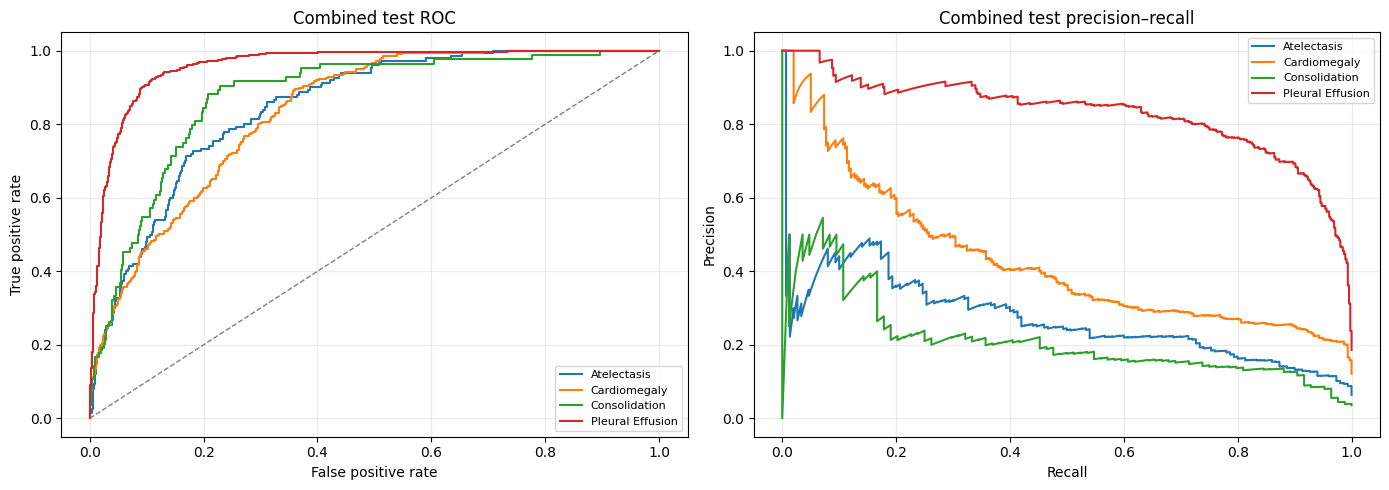

In [11]:
# Plot masked ROC and precision-recall curves for the combined test set
from sklearn.metrics import precision_recall_curve, roc_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for index, (label, target, mask) in enumerate(zip(LABELS, TARGETS, MASKS)):
    observed = test_df[mask].to_numpy(dtype=bool)
    truth = test_df.loc[observed, target].to_numpy(dtype=int)
    probability = scores[observed, index]
    if np.unique(truth).size == 2:
        fpr, tpr, _ = roc_curve(truth, probability)
        axes[0].plot(fpr, tpr, label=label)
    if truth.sum():
        precision, recall, _ = precision_recall_curve(truth, probability)
        axes[1].plot(recall, precision, label=label)
axes[0].plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
axes[0].set(title='Combined test ROC', xlabel='False positive rate', ylabel='True positive rate')
axes[1].set(title='Combined test precision–recall', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS / 'roc_pr_curves.png', dpi=180)
plt.show()
plt.close(fig)


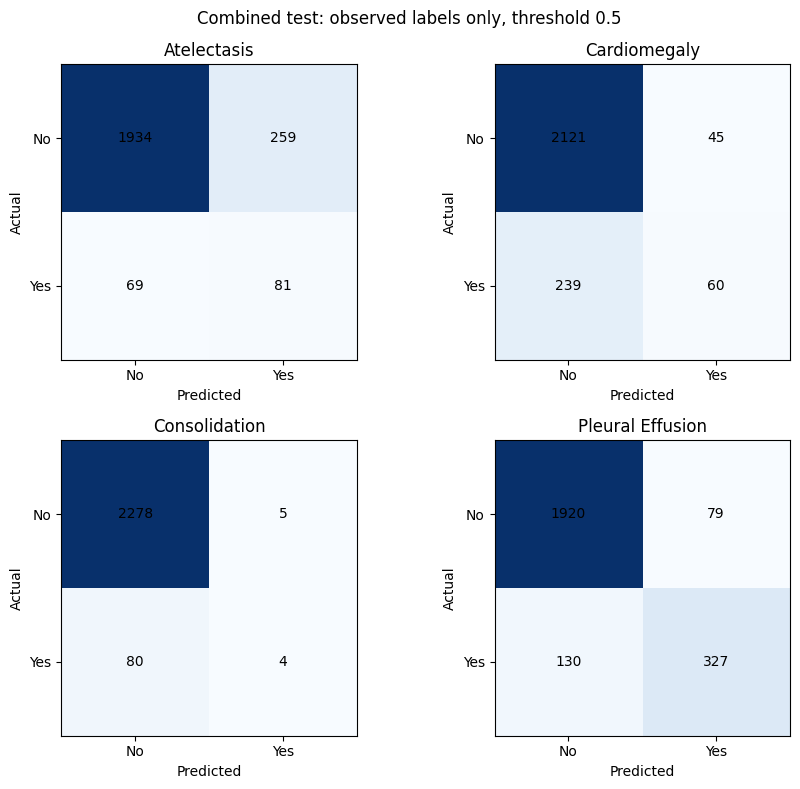

In [12]:
# Plot observed-label confusion matrices at the fixed 0.5 threshold
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for index, (label, target, mask) in enumerate(zip(LABELS, TARGETS, MASKS)):
    observed = test_df[mask].to_numpy(dtype=bool)
    truth = test_df.loc[observed, target].to_numpy(dtype=int)
    predicted = (scores[observed, index] > 0.5).astype(int)
    matrix = confusion_matrix(truth, predicted, labels=[0, 1])
    ax = axes.flat[index]
    ax.imshow(matrix, cmap='Blues')
    for row in range(2):
        for column in range(2):
            ax.text(column, row, str(matrix[row, column]), ha='center', va='center', fontsize=10)
    ax.set(title=label, xticks=[0, 1], yticks=[0, 1],
           xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'],
           xlabel='Predicted', ylabel='Actual')
fig.suptitle('Combined test: observed labels only, threshold 0.5')
fig.tight_layout()
fig.savefig(RESULTS / 'confusion_matrices.png', dpi=180)
plt.show()
plt.close(fig)


In [13]:
# Save predictions, source-specific metrics, configuration, and measured time
predictions_df = test_df[['sample_id', 'source_dataset', 'group_id', 'image_path', *TARGETS, *MASKS]].copy()
for index, key in enumerate(KEYS):
    predictions_df['score_' + key] = scores[:, index]
    predictions_df['prediction_' + key] = (scores[:, index] > 0.5).astype(np.uint8)
predictions_df.to_csv(RESULTS / 'predictions.csv', index=False)
metrics_df.to_csv(RESULTS / 'metrics.csv', index=False)

def sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as source:
        for block in iter(lambda: source.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

run_info = {
    'protocol': 'released AlphaRAD zero-shot inference on combined CheXpert-VinDr held-out test',
    'source_repository': REPO_URL,
    'source_commit': REPO_COMMIT,
    'checkpoint': str(CHECKPOINT),
    'checkpoint_sha256': sha256(CHECKPOINT),
    'model_revision': MODEL_REVISION,
    'text_revision': TEXT_REVISION,
    'image_revision': IMAGE_REVISION,
    'archive': str(ARCHIVE_PATH),
    'archive_size_bytes': ARCHIVE_PATH.stat().st_size,
    'archive_settings': settings,
    'test_images': len(test_df),
    'test_sources': test_df['source_dataset'].value_counts().to_dict(),
    'queries': LABELS,
    'task_training_epochs': TASK_EPOCHS,
    'seed': SEED,
    'inference_batch_size': INFERENCE_BATCH_SIZE,
    'threshold': 0.5,
    'mask_rule': 'evaluate each target only where its corresponding mask is 1',
    'evaluation_seconds': EVAL_SECONDS,
    'total_seconds': time.perf_counter() - RUN_START,
    'gpu': torch.cuda.get_device_name(0),
}
(RESULTS / 'run_info.json').write_text(json.dumps(run_info, indent=2))
print('Saved results to:', RESULTS)
print(f'Total notebook time: {run_info["total_seconds"] / 60:.1f} minutes')


Saved results to: /kaggle/working/alpharad_combined_results
Total notebook time: 7.0 minutes
